# Degradation EDA

In [1]:
import os
from pathlib import Path

# configs/base.yaml is resolved relative to the repo root
if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from f1_strategy_engine.constants import PointInTimeMode
from f1_strategy_engine.features.build import build_modelling_table

CIRCUITS = ["Sakhir", "Monza"]
COMPOUND_COLOURS = {"SOFT": "#d62728", "MEDIUM": "#e6a800", "HARD": "#4a4a4a"}
MIN_LAPS_PER_POINT = 5  # hide the median where too few stints are this long

sns.set_theme(style="whitegrid", context="notebook")

## Load

In [2]:
table = build_modelling_table(pd.Timestamp.now(tz="UTC"), PointInTimeMode.ROWS_ONLY)

df = table[table["circuit"].isin(CIRCUITS)].copy()
df["circuit"] = df["circuit"].cat.remove_unused_categories()
df["compound"] = df["compound"].cat.remove_unused_categories()
df.shape

(2137, 25)

## Noise: what the silver flags exclude

In [3]:
excluded = pd.DataFrame(
    {
        "lap 1": df["is_lap1"],
        "in-lap": df["is_inlap"],
        "out-lap": df["is_outlap"],
        "SC": df["is_safety_car_lap"],
        "VSC": df["is_vsc_lap"],
        "inaccurate": ~df["is_accurate"].fillna(False),
        "deleted": df["deleted"].fillna(True),
        "generated": df["fastf1_generated"],
    }
)
representative = ~excluded.any(axis=1) & df["fuel_corrected_lap_time"].notna()

summary = excluded.groupby(df["circuit"], observed=True).mean()
summary["kept"] = representative.groupby(df["circuit"], observed=True).mean()
summary.mul(100).round(1)  # % of laps

,lap 1,in-lap,out-lap,SC,VSC,inaccurate,deleted,generated,kept
circuit,,,,,,,,,
Monza,2.0,3.1,3.0,0.0,0.0,8.0,1.3,0.0,90.7
Sakhir,1.8,3.8,3.8,0.0,0.0,9.3,1.8,0.0,89.0


In [4]:
clean = df[representative].astype(
    {
        "tyre_age": float,
        "stint_lap_index": float,
        "fuel_corrected_lap_time": float,
        "delta_to_stint_baseline": float,
    }
)

# Sample size per cell: thin cells are where per-(circuit x compound) fits get unstable
by_cell = clean.groupby(["circuit", "compound"], observed=True)
pd.DataFrame(
    {
        "stints": by_cell[["driver", "stint"]].apply(
            lambda g: len(g.drop_duplicates())
        ),
        "laps": by_cell.size(),
    }
)

stints  laps
circuit compound              
Monza   SOFT           1     1
        MEDIUM        19   236
        HARD          30   677
Sakhir  SOFT          25   284
        HARD          37   721

## 1. Fuel-corrected lap time vs tyre age

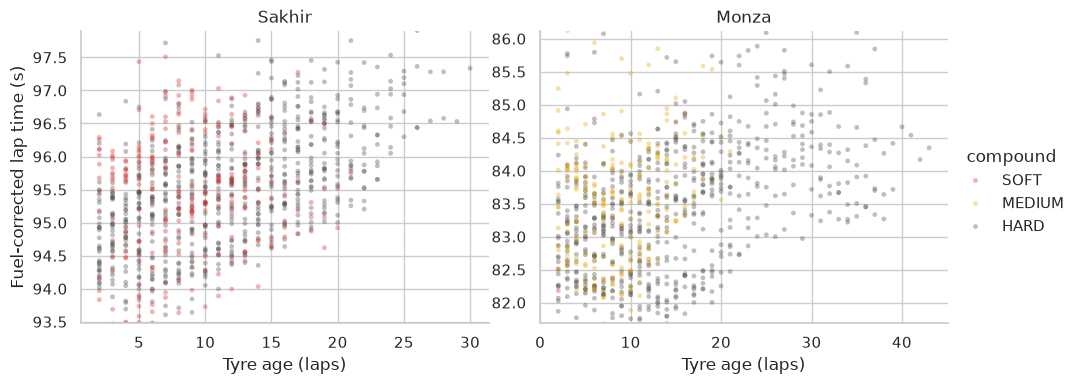

In [5]:
g = sns.relplot(
    data=clean,
    x="tyre_age",
    y="fuel_corrected_lap_time",
    hue="compound",
    col="circuit",
    col_order=CIRCUITS,
    palette=COMPOUND_COLOURS,
    hue_order=[c for c in COMPOUND_COLOURS if c in set(clean["compound"])],
    s=12,
    alpha=0.35,
    linewidth=0,
    facet_kws={"sharey": False, "sharex": False},
    height=4,
    aspect=1.2,
)
for circuit, ax in g.axes_dict.items():
    y = clean.loc[clean["circuit"] == circuit, "fuel_corrected_lap_time"]
    ax.set_ylim(y.quantile(0.01), y.quantile(0.99))
g.set_axis_labels("Tyre age (laps)", "Fuel-corrected lap time (s)")
g.set_titles("{col_name}")
plt.show()

## 2. Delta to stint baseline vs lap in stint

Subtracting each stint's own baseline removes the car/driver offset. Line = median per lap, band = interquartile range.

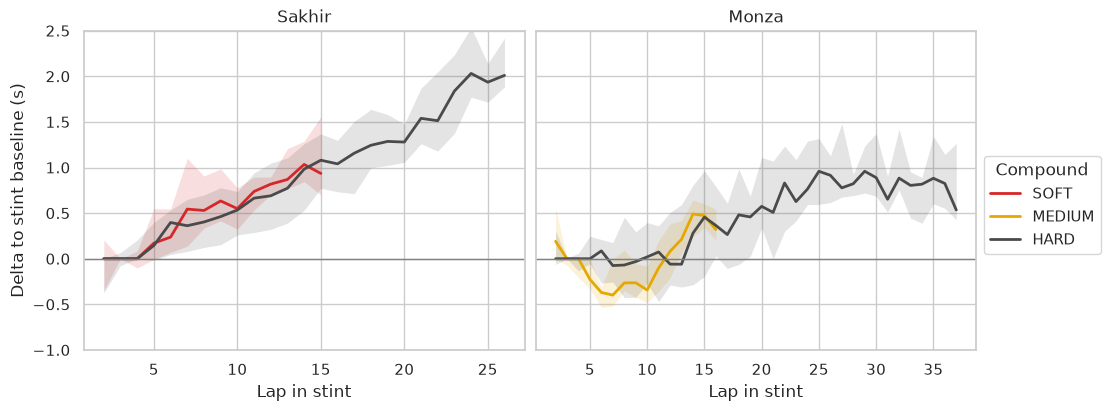

In [6]:
deltas = clean.dropna(subset=["delta_to_stint_baseline"])
per_lap = (
    deltas.groupby(["circuit", "compound", "stint_lap_index"], observed=True)[
        "delta_to_stint_baseline"
    ]
    .describe()[["count", "25%", "50%", "75%"]]
    .query("count >= @MIN_LAPS_PER_POINT")
    .reset_index()
)

fig, axes = plt.subplots(
    1, len(CIRCUITS), figsize=(11, 4), sharey=True, layout="constrained"
)
for ax, circuit in zip(axes, CIRCUITS, strict=True):
    for compound, colour in COMPOUND_COLOURS.items():
        sub = per_lap[
            (per_lap["circuit"] == circuit) & (per_lap["compound"] == compound)
        ]
        if sub.empty:
            continue
        ax.fill_between(
            sub["stint_lap_index"],
            sub["25%"],
            sub["75%"],
            color=colour,
            alpha=0.15,
            linewidth=0,
        )
        ax.plot(sub["stint_lap_index"], sub["50%"], color=colour, linewidth=2)
    ax.axhline(0, color="grey", linewidth=1)
    ax.set_title(circuit)
    ax.set_xlabel("Lap in stint")
axes[0].set_ylabel("Delta to stint baseline (s)")
axes[0].set_ylim(-1, 2.5)
present = [c for c in COMPOUND_COLOURS if c in set(per_lap["compound"])]
fig.legend(
    [plt.Line2D([], [], color=COMPOUND_COLOURS[c], linewidth=2) for c in present],
    present,
    title="Compound",
    loc="outside right center",
)
plt.show()

## Naive linear slope

In [ ]:
# Ordinary least squares slope
def ols_slope(cell: pd.DataFrame) -> float:
    x, y = cell["stint_lap_index"], cell["delta_to_stint_baseline"]
    return x.cov(y) / x.var()


slopes = deltas.groupby(["circuit", "compound"], observed=True).apply(
    ols_slope, include_groups=False
)
slopes.rename("s_per_lap").round(3)

circuit  compound
Monza    MEDIUM      0.028
         HARD        0.035
Sakhir   SOFT        0.093
         HARD        0.092
Name: s_per_lap, dtype: float64